# X-Ray Radiography -- Geometric Effects

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-04.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Static version

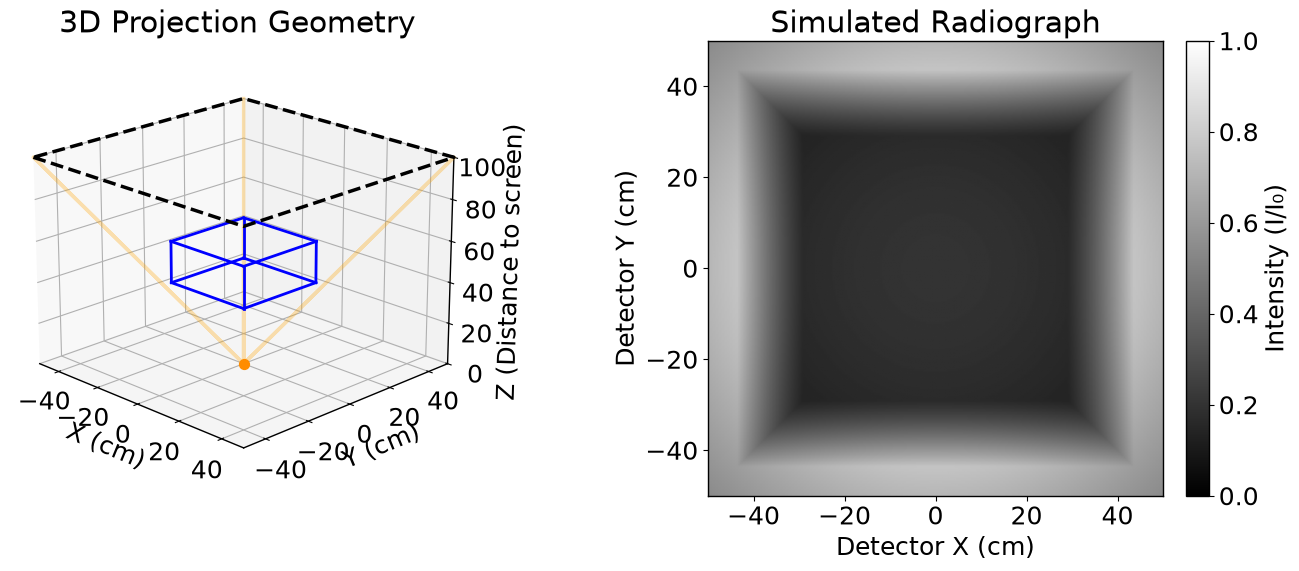

In [3]:
# --- Fixed Simulation Parameters ---
N = 300               # Grid resolution (N x N)
d = 100.0             # Detector distance (z=100 cm)
det_size = 100.0      # Detector spans -50 to 50 cm in x and y
w = 35.0              # Object width/height (35 cm)
L = 20.0              # Object thickness (20 cm)
z_c = 50.0            # Object center Z-position (50 cm)
mu = 0.08             # Linear attenuation coefficient

# Calculate front and back faces of the object
z1 = z_c - L/2
z2 = z_c + L/2

# ----------------------------------------------------
# 1. MATHEMATICAL CALCULATIONS (Vectorized)
# ----------------------------------------------------
# Precompute detector pixel coordinates
x_lin = np.linspace(-det_size/2, det_size/2, N)
y_lin = np.linspace(-det_size/2, det_size/2, N)
xx, yy = np.meshgrid(x_lin, y_lin)

# Prevent division by zero during ray tracing
xx_safe = np.where(xx == 0, 1e-9, xx)
yy_safe = np.where(yy == 0, 1e-9, yy)

# Ray distance from source to detector pixel
r_det = np.sqrt(xx**2 + yy**2 + d**2)
cos_theta = d / r_det

# Combined Baseline Intensity: Inverse-Square (cos^2) * Obliquity (cos)
I = cos_theta**3
    
# AABB Ray Intersection for Rectangular Prism
tx1, tx2 = (-w/2) / xx_safe, (w/2) / xx_safe
txmin, txmax = np.minimum(tx1, tx2), np.maximum(tx1, tx2)

ty1, ty2 = (-w/2) / yy_safe, (w/2) / yy_safe
tymin, tymax = np.minimum(ty1, ty2), np.maximum(ty1, ty2)

tzmin, tzmax = z1 / d, z2 / d

# Entry and exit parameters along the ray
tin = np.maximum.reduce([txmin, tymin, np.full_like(txmin, tzmin)])
tout = np.minimum.reduce([txmax, tymax, np.full_like(txmax, tzmax)])

# Identify which rays hit the object
hit = (tin < tout) & (tout > 0)

# Attenuation and Path Length (Effect is ON)
delta_t = np.where(hit, tout - tin, 0)
L_eff = delta_t * r_det
    
transmission = np.exp(-mu * L_eff)
final_image = I * transmission

# ----------------------------------------------------
# 2. PLOT LEFT: 3D GEOMETRY SETUP
# ----------------------------------------------------
fig1 = plt.figure(figsize=(14, 6))

ax1 = fig1.add_subplot(1, 2, 1, projection='3d')
ax1.set_title("3D Projection Geometry")

# Plot Source
ax1.scatter([0], [0], [0], color='darkorange', s=50, label='Source')

# Plot FOV Cone (Rays)
edges_x = [0, -50, 0, 50, 0, 50, 0, -50]
edges_y = [0, -50, 0, -50, 0, 50, 0, 50]
edges_z = [0, d, 0, d, 0, d, 0, d]
ax1.plot(edges_x, edges_y, edges_z, color='orange', alpha=0.3)

# Plot Object (Wireframe Box)
v = np.array([
    [-w/2, -w/2, z1], [w/2, -w/2, z1], [w/2, w/2, z1], [-w/2, w/2, z1], # Front face
    [-w/2, -w/2, z2], [w/2, -w/2, z2], [w/2, w/2, z2], [-w/2, w/2, z2]  # Back face
])
box_edges = [(0,1), (1,2), (2,3), (3,0), (4,5), (5,6), (6,7), (7,4), (0,4), (1,5), (2,6), (3,7)]
for edge in box_edges:
    ax1.plot(*zip(v[edge[0]], v[edge[1]]), color='blue', linewidth=2)
    
# Plot Detector Plane boundary
ax1.plot([-50, 50, 50, -50, -50], [-50, -50, 50, 50, -50], [d, d, d, d, d], color='black', linestyle='--')

ax1.set_xlim([-50, 50])
ax1.set_ylim([-50, 50])
ax1.set_zlim([0, 100])
ax1.set_xlabel('X (cm)')
ax1.set_ylabel('Y (cm)')
ax1.set_zlabel('Z (Distance to screen)')
ax1.view_init(elev=20, azim=-45)

# ----------------------------------------------------
# 3. PLOT RIGHT: 2D DETECTOR IMAGE
# ----------------------------------------------------
ax2 = fig1.add_subplot(1, 2, 2)
ax2.set_title("Simulated Radiograph")

im = ax2.imshow(
    final_image, 
    extent=[-det_size/2, det_size/2, -det_size/2, det_size/2], 
    origin='lower', 
    cmap='gray', 
    vmin=0, vmax=1
)

ax2.set_xlabel('Detector X (cm)')
ax2.set_ylabel('Detector Y (cm)')
plt.colorbar(im, ax=ax2, label='Intensity (I/I₀)', fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## Interactive version

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interactive, Checkbox, FloatSlider, VBox, HBox, Layout
from IPython.display import display

# --- Fixed Simulation Parameters ---
N2 = 250               # Grid resolution (N2 x N2)
d2 = 100.0             # Detector distance (z=100)
det_size2 = 100.0      # Detector spans -50 to 50 in x and y
w2 = 35.0              # Fixed object width/height
L2 = 20.0              # Fixed object thickness
mu2 = 0.08             # Linear attenuation coefficient

# Precompute detector pixel coordinates
x_lin2 = np.linspace(-det_size2/2, det_size2/2, N2)
y_lin2 = np.linspace(-det_size2/2, det_size2/2, N2)
xx2, yy2 = np.meshgrid(x_lin2, y_lin2)

# Prevent division by zero during ray tracing by adding a tiny epsilon
xx_safe2 = np.where(xx2 == 0, 1e-9, xx2)
yy_safe2 = np.where(yy2 == 0, 1e-9, yy2)

# Ray distance from source to detector pixel
r_det2 = np.sqrt(xx2**2 + yy2**2 + d2**2)
cos_theta2 = d2 / r_det2

def update_plot(z_c, isq_on, obq_on, path_on):
    fig = plt.figure(figsize=(14, 6))
    
    # ----------------------------------------------------
    # 1. MATHEMATICAL CALCULATIONS (Vectorized)
    # ----------------------------------------------------
    z1 = z_c - L2/2
    z2 = z_c + L2/2
    
    # Baseline Intensity (ISQ & Obliquity)
    I = np.ones_like(xx2)
    if isq_on:
        I *= (cos_theta2**2)
    if obq_on:
        I *= cos_theta2
        
    # AABB Ray Intersection for Rectangular Prism
    tx1, tx2 = (-w2/2) / xx_safe2, (w2/2) / xx_safe2
    txmin, txmax = np.minimum(tx1, tx2), np.maximum(tx1, tx2)
    
    ty1, ty2 = (-w2/2) / yy_safe2, (w2/2) / yy_safe2
    tymin, tymax = np.minimum(ty1, ty2), np.maximum(ty1, ty2)
    
    tzmin, tzmax = z1 / d2, z2 / d2
    
    # Entry and exit parameters along the ray
    tin = np.maximum.reduce([txmin, tymin, np.full_like(txmin, tzmin)])
    tout = np.minimum.reduce([txmax, tymax, np.full_like(txmax, tzmax)])
    
    # Identify which rays hit the object
    hit = (tin < tout) & (tout > 0)
    
    # Attenuation and Path Length
    if path_on:
        delta_t = np.where(hit, tout - tin, 0)
        L_eff = delta_t * r_det2
    else:
        # Treat as flat 2D square cutout (pure thickness)
        L_eff = np.where(hit, L2, 0)
        
    transmission = np.exp(-mu2 * L_eff)
    final_image = I * transmission

    # ----------------------------------------------------
    # 2. PLOT LEFT: 3D GEOMETRY SETUP
    # ----------------------------------------------------
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    ax1.set_title("3D Projection Geometry")
    
    # Plot Source
    ax1.scatter([0], [0], [0], color='darkorange', s=50, label='Source')
    
    # Plot FOV Cone (Rays)
    edges_x = [0, -50, 0, 50, 0, 50, 0, -50]
    edges_y = [0, -50, 0, -50, 0, 50, 0, 50]
    edges_z = [0, 100, 0, 100, 0, 100, 0, 100]
    ax1.plot(edges_x, edges_y, edges_z, color='orange', alpha=0.3)
    
    # Plot Object (Wireframe Box)
    v = np.array([
        [-w2/2, -w2/2, z1], [w2/2, -w2/2, z1], [w2/2, w2/2, z1], [-w2/2, w2/2, z1], # Front face
        [-w2/2, -w2/2, z2], [w2/2, -w2/2, z2], [w2/2, w2/2, z2], [-w2/2, w2/2, z2]  # Back face
    ])
    box_edges = [(0,1), (1,2), (2,3), (3,0), (4,5), (5,6), (6,7), (7,4), (0,4), (1,5), (2,6), (3,7)]
    for edge in box_edges:
        ax1.plot(*zip(v[edge[0]], v[edge[1]]), color='blue', linewidth=2)
        
    # Plot Detector Plane boundary
    ax1.plot([-50, 50, 50, -50, -50], [-50, -50, 50, 50, -50], [100, 100, 100, 100, 100], color='black', linestyle='--')

    ax1.set_xlim([-50, 50])
    ax1.set_ylim([-50, 50])
    ax1.set_zlim([0, 100])
    ax1.set_xlabel('X (cm)')
    ax1.set_ylabel('Y (cm)')
    ax1.set_zlabel('Z (Distance to screen)')
    ax1.view_init(elev=20, azim=-45)

    # ----------------------------------------------------
    # 3. PLOT RIGHT: 2D DETECTOR IMAGE
    # ----------------------------------------------------
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.set_title("Simulated Radiograph")
    
    im = ax2.imshow(
        final_image, 
        extent=[-det_size2/2, det_size2/2, -det_size2/2, det_size2/2], 
        origin='lower', 
        cmap='gray', 
        vmin=0, vmax=1
    )
    
    ax2.set_xlabel('Detector X (cm)')
    ax2.set_ylabel('Detector Y (cm)')
    plt.colorbar(im, ax=ax2, label='Intensity ($I/I_0$)', fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    plt.show()

# --- Create ipywidgets UI ---
slider_z = FloatSlider(value=50.0, min=20.0, max=80.0, step=1.0, description='Object Z-pos:', layout=Layout(width='400px'))
check_isq = Checkbox(value=True, description='Inverse-Square Law')
check_obq = Checkbox(value=True, description='Obliquity')
check_path = Checkbox(value=True, description='Path Length')

ui = VBox([
    slider_z,
    HBox([check_isq, check_obq, check_path])
])

out = interactive(update_plot, z_c=slider_z, isq_on=check_isq, obq_on=check_obq, path_on=check_path)
display(ui, out.children[-1])

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch08/ch08-04_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-04.html) (direct link: [ch08-04_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch08/ch08-04_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.